In [1]:
# CELDA 1 — Instalar dependencias (ejecutar si no lo hiciste)
!pip install -q tensorflow opencv-python-headless scikit-learn matplotlib seaborn

In [1]:
# @title CELDA 3: Verificación de Estructura y Conteo de Imágenes Final
import os

# --- 1. CONFIGURACIÓN ---
# Definimos la carpeta aquí mismo para asegurar que funcione
DATA_DIR = 'dataset_maiz'

# Lista de cosas que NO son clases (basura del sistema)
NON_CLASS_ARTIFACTS = ['__MACOSX', '.ipynb_checkpoints', '.DS_Store']

# --- 2. FUNCIONES ---
def count_images(folder):
    """Cuenta archivos de imagen (jpg, png, etc.) en la carpeta dada."""
    cnt = 0
    valid_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')
    
    if os.path.isdir(folder):
        for f in os.listdir(folder):
            if f.lower().endswith(valid_exts):
                cnt += 1
    return cnt

# --- 3. EJECUCIÓN PRINCIPAL ---
print(f"🔍 Verificando carpeta: '{DATA_DIR}'...\n")

if not os.path.exists(DATA_DIR):
    print(f"❌ ERROR: No se encontró la carpeta '{DATA_DIR}'.")
    print("   👉 Asegúrate de haber ejecutado la descompresión (Celda 2) correctamente.")
else:
    try:
        # Listar todo el contenido de la carpeta principal
        all_items = os.listdir(DATA_DIR)

        # FILTRO INTELIGENTE:
        # 1. Debe ser una carpeta (isdir)
        # 2. No debe estar en la lista de prohibidos (NON_CLASS_ARTIFACTS)
        # 3. No debe empezar con punto (archivos ocultos de Linux/Colab)
        classes = sorted([d for d in all_items
                          if os.path.isdir(os.path.join(DATA_DIR, d))
                          and d not in NON_CLASS_ARTIFACTS
                          and not d.startswith('.')])

        num_classes = len(classes)

        if num_classes == 0:
            print("⚠️ ALERTA: La carpeta existe, pero NO se detectaron subcarpetas de clases.")
            print(f"   Contenido encontrado: {all_items}")
        else:
            print(f"✅ Clases detectadas ({num_classes}): {classes}")
            print("-" * 40)
            print(f"{'CLASE':<20} | {'IMÁGENES':<10}")
            print("-" * 40)

            total_images = 0

            # Contar imágenes por cada clase
            for c in classes:
                path_to_class = os.path.join(DATA_DIR, c)
                num_images = count_images(path_to_class)
                
                print(f"{c:<20} | {num_images:<10}")
                total_images += num_images

            print("-" * 40)
            print(f"📊 TOTAL GENERAL:      {total_images}")
            print("-" * 40)

    except Exception as e:
        print(f"\n❌ Ocurrió un error inesperado al leer los archivos: {e}")

🔍 Verificando carpeta: 'dataset_maiz'...

✅ Clases detectadas (4): ['mancha_gris_foliar', 'roya_comun', 'sana', 'tizon_foliar']
----------------------------------------
CLASE                | IMÁGENES  
----------------------------------------
mancha_gris_foliar   | 164       
roya_comun           | 107       
sana                 | 911       
tizon_foliar         | 154       
----------------------------------------
📊 TOTAL GENERAL:      1336
----------------------------------------


In [2]:
# @title CELDA 4: Balanceo con Filtros Específicos (Rotación +/- 5, Brillo 20%)
import os
import shutil
import random
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img

# --- CONFIGURACIÓN DE RUTAS ---
INPUT_DIR = 'dataset_maiz'           # Carpeta original (Desbalanceada)
OUTPUT_DIR = 'dataset_balanceado'    # Carpeta nueva (Balanceada)
TARGET_AMOUNT = 950                  # Meta: Superar un poco a la clase Sana (que tiene 911)

# --- CONFIGURACIÓN DE FILTROS (TUS REQUERIMIENTOS) ---
datagen = ImageDataGenerator(
    rotation_range=5,            # ✅ ROTACIÓN: Aleatoria entre -5° y +5°
    brightness_range=[0.8, 1.2], # ✅ BRILLO: Variación del 20% (Más oscuro / Más claro)
    zoom_range=0.15,             # ZOOM: 15% (Sutil, para simular distancia)
    width_shift_range=0.1,       # DESPLAZAMIENTO HORIZONTAL: 10%
    height_shift_range=0.1,      # DESPLAZAMIENTO VERTICAL: 10%
    horizontal_flip=True,        # ESPEJO: Vital, una hoja vale por dos
    fill_mode='nearest'          # Relleno de bordes suave
)

# --- LIMPIEZA Y PREPARACIÓN ---
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR) # Borra la carpeta anterior si existe para no duplicar
os.makedirs(OUTPUT_DIR)

print(f"⚙️ Configuración de Aumento:")
print(f"   - Rotación: ±5 grados")
print(f"   - Brillo: ±20%")
print(f"   - Meta por clase: {TARGET_AMOUNT} imágenes")
print("-" * 50)

# --- PROCESO DE GENERACIÓN ---
classes = sorted(os.listdir(INPUT_DIR))

for class_name in classes:
    class_input_path = os.path.join(INPUT_DIR, class_name)
    
    # Ignorar archivos sueltos, solo carpetas
    if not os.path.isdir(class_input_path): continue
    
    class_output_path = os.path.join(OUTPUT_DIR, class_name)
    os.makedirs(class_output_path, exist_ok=True)
    
    # 1. Identificar imágenes originales
    images = [f for f in os.listdir(class_input_path) 
              if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))]
    original_count = len(images)
    
    print(f"📂 Procesando clase: '{class_name}'")
    print(f"   - Originales encontradas: {original_count}")

    # 2. Copiar las originales (¡Son las más importantes!)
    for img in images:
        shutil.copy(os.path.join(class_input_path, img), os.path.join(class_output_path, img))

    # 3. Calcular cuántas faltan para llegar a 950
    needed = TARGET_AMOUNT - original_count
    
    if needed <= 0:
        print(f"   ✅ Clase completa. No se requiere aumento.")
    else:
        print(f"   🚀 Faltan {needed}. Generando clones mejorados...")
        
        generated_count = 0
        while generated_count < needed:
            # Elegir una imagen original al azar
            random_img_name = random.choice(images)
            img_path = os.path.join(class_input_path, random_img_name)
            
            try:
                # Cargar imagen y convertir a arreglo
                img = load_img(img_path)
                x = img_to_array(img)
                x = x.reshape((1,) + x.shape) # Formato (1, alto, ancho, canales)
                
                # Generar transformación
                for batch in datagen.flow(x, batch_size=1, 
                                          save_to_dir=class_output_path, 
                                          save_prefix='aug', 
                                          save_format='jpg'):
                    generated_count += 1
                    break # Romper el bucle interno (solo queremos 1 foto por vuelta)
            except Exception as e:
                print(f"   ⚠️ Error con la imagen {random_img_name}: {e}")

        print(f"   ✨ ¡Hecho! Se crearon {generated_count} imágenes nuevas.")
    
    # Verificación final de la carpeta
    final_count = len(os.listdir(class_output_path))
    print(f"   📊 Total final en carpeta: {final_count}")
    print("-" * 50)

print(f"\n✅ DATASET BALANCEADO LISTO EN: {OUTPUT_DIR}")

⚙️ Configuración de Aumento:
   - Rotación: ±5 grados
   - Brillo: ±20%
   - Meta por clase: 950 imágenes
--------------------------------------------------
📂 Procesando clase: 'mancha_gris_foliar'
   - Originales encontradas: 164
   🚀 Faltan 786. Generando clones mejorados...
   ✨ ¡Hecho! Se crearon 786 imágenes nuevas.
   📊 Total final en carpeta: 908
--------------------------------------------------
📂 Procesando clase: 'roya_comun'
   - Originales encontradas: 107
   🚀 Faltan 843. Generando clones mejorados...
   ✨ ¡Hecho! Se crearon 843 imágenes nuevas.
   📊 Total final en carpeta: 908
--------------------------------------------------
📂 Procesando clase: 'sana'
   - Originales encontradas: 911
   🚀 Faltan 39. Generando clones mejorados...
   ✨ ¡Hecho! Se crearon 39 imágenes nuevas.
   📊 Total final en carpeta: 950
--------------------------------------------------
📂 Procesando clase: 'tizon_foliar'
   - Originales encontradas: 154
   🚀 Faltan 796. Generando clones mejorados...
  

In [5]:
# @title CELDA 5: División 70/15/15 y Creación de tf.data (Dataset Balanceado)
import os
import glob
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# --- 1. CONFIGURACIÓN ---
# Usamos explícitamente la carpeta que acabamos de crear en la Celda 4
DATASET_PATH = 'dataset_desbalanceado'
IMG_SIZE = 224 # Tamaño estándar para EfficientNet/ResNet
BATCH_SIZE = 32

print(f"📂 Cargando imágenes desde: {DATASET_PATH}")

# --- 2. CARGAR RUTAS Y ETIQUETAS ---
try:
    # Obtener nombres de clases ordenados alfabéticamente
    class_names = sorted([d for d in os.listdir(DATASET_PATH) 
                          if os.path.isdir(os.path.join(DATASET_PATH, d))])
    num_classes = len(class_names)
    print(f"✅ Clases detectadas ({num_classes}): {class_names}")

    filepaths = []
    labels = []

    for idx, cls in enumerate(class_names):
        class_dir = os.path.join(DATASET_PATH, cls)
        # Buscar imágenes recursivamente
        for root, dirs, files in os.walk(class_dir):
            for f in files:
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                    filepaths.append(os.path.join(root, f))
                    labels.append(idx)
    
    print(f"📊 Total de imágenes encontradas: {len(filepaths)}")

except FileNotFoundError:
    print(f"❌ ERROR: No existe la carpeta '{DATASET_PATH}'. Ejecuta la Celda 4 primero.")
    raise

# --- 3. DIVISIÓN ESTRATIFICADA (70% Train - 15% Val - 15% Test) ---
# Convertir a numpy para facilitar manejo
filepaths = np.array(filepaths)
labels = np.array(labels)

# PASO A: Separar el 15% para TEST (El resto es 85%)
X_temp, X_test, y_temp, y_test = train_test_split(
    filepaths, labels, 
    test_size=0.15, 
    stratify=labels, 
    random_state=42
)

# PASO B: Separar el 15% (del total original) para VALIDACIÓN
# Como nos queda el 85% de los datos, calculamos: 15 / 85 = 0.1765
val_split = 0.15 / 0.85 
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, 
    test_size=val_split, 
    stratify=y_temp, 
    random_state=42
)

print("-" * 50)
print(f"TRAIN (Entrenamiento 70%): {len(X_train)} imágenes")
print(f"VAL   (Validación 15%):    {len(X_val)} imágenes")
print(f"TEST  (Prueba 15%):        {len(X_test)} imágenes")
print("-" * 50)

# --- 4. CONSTRUCCIÓN DE TF.DATA (Optimización) ---

def process_path(file_path, label):
    """Carga, decodifica y redimensiona la imagen"""
    # Cargar archivo
    img = tf.io.read_file(file_path)
    # Decodificar (detecta jpg o png automáticamente)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    # Convertir a float32 y normalizar [0,1]
    img = tf.cast(img, tf.float32) / 255.0
    # Redimensionar (EfficientNet necesita tamaño fijo)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return img, label

def configure_for_performance(ds, is_train=False):
    """Optimiza el pipeline de carga"""
    # Cachear en memoria si cabe, sino en disco
    # ds = ds.cache() 
    if is_train:
        ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    return ds

# Crear los Datasets de TensorFlow
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Mapear la función de procesamiento
train_ds = train_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)

# Optimizar rendimiento
train_dataset = configure_for_performance(train_ds, is_train=True)
val_dataset = configure_for_performance(val_ds)
test_dataset = configure_for_performance(test_ds)

print("✅ Pipelines de tf.data creados exitosamente.")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Image Size: {IMG_SIZE}x{IMG_SIZE}")

📂 Cargando imágenes desde: dataset_desbalanceado
✅ Clases detectadas (3): ['roya_comun', 'sana', 'tizon_foliar']
📊 Total de imágenes encontradas: 2001
--------------------------------------------------
TRAIN (Entrenamiento 70%): 1400 imágenes
VAL   (Validación 15%):    300 imágenes
TEST  (Prueba 15%):        301 imágenes
--------------------------------------------------
✅ Pipelines de tf.data creados exitosamente.
   Batch size: 32
   Image Size: 224x224


Model: "DenseNet121_Maiz"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_1 (Add)                     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_3 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,040,579 (26.86 MB)

 Trainable params: 3,075 (12.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

...

44/44 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.8943 - loss: 0.2712 - val_accuracy: 0.9033 - val_loss: 0.2896
Epoch 38/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9047 - loss: 0.2515
Epoch 38: val_accuracy did not improve from 0.90333
44/44 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.8957 - loss: 0.2736 - val_accuracy: 0.8967 - val_loss: 0.2901
Epoch 39/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8931 - loss: 0.2507
Epoch 39: val_accuracy improved from 0.90333 to 0.91000, saving model to mejor_modelo_densenet121.h5


44/44 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.8900 - loss: 0.2601 - val_accuracy: 0.9100 - val_loss: 0.2816
Epoch 40/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8867 - loss: 0.2656
Epoch 40: val_accuracy did not improve from 0.91000
44/44 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.8857 - loss: 0.2711 - val_accuracy: 0.9067 - val_loss: 0.2852
Epoch 41/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8720 - loss: 0.3101
Epoch 41: val_accuracy did not improve from 0.91000
44/44 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.8950 - loss: 0.2761 - val_accuracy: 0.8933 - val_loss: 0.2966
Epoch 42/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9312 - loss: 0.2198
Epoch 42: val_accuracy did not improve from 0.91000
44/44 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.9079 - loss: 0.2419 - val_accuracy: 0.8967 - val_loss: 0.2942
Epoch 43/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9092 - loss: 0.2430
Epoch 43: val_accuracy did not improve fro

44/44 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.8900 - loss: 0.2719 - val_accuracy: 0.9133 - val_loss: 0.2748
Epoch 55/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8890 - loss: 0.2595
Epoch 55: val_accuracy did not improve from 0.91333
44/44 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.8957 - loss: 0.2608 - val_accuracy: 0.9067 - val_loss: 0.2736
Epoch 56/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9168 - loss: 0.2264
Epoch 56: val_accuracy did not improve from 0.91333
44/44 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.9043 - loss: 0.2377 - val_accuracy: 0.9100 - val_loss: 0.2779
Epoch 57/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9019 - loss: 0.2459
Epoch 57: val_accuracy did not improve from 0.91333
44/44 ━━━━━━━━━━━━━━━━━━━━ 346s 3s/step - accuracy: 0.9007 - loss: 0.2497 - val_accuracy: 0.9067 - val_loss: 0.2652
Epoch 58/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8856 - loss: 0.2595
Epoch 58: val_accuracy did not improve fro

44/44 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.9057 - loss: 0.2312 - val_accuracy: 0.9200 - val_loss: 0.2579
Epoch 68/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9091 - loss: 0.2599
Epoch 68: val_accuracy did not improve from 0.92000
44/44 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.9086 - loss: 0.2513 - val_accuracy: 0.9000 - val_loss: 0.2834
Epoch 69/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9022 - loss: 0.2447
Epoch 69: val_accuracy did not improve from 0.92000
44/44 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.9079 - loss: 0.2354 - val_accuracy: 0.9200 - val_loss: 0.2660
Epoch 70/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9002 - loss: 0.2435
Epoch 70: val_accuracy did not improve from 0.92000
44/44 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.8993 - loss: 0.2399 - val_accuracy: 0.9100 - val_loss: 0.2694
Epoch 71/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9072 - loss: 0.2287
Epoch 71: val_accuracy did not improve from 

44/44 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.9214 - loss: 0.2264 - val_accuracy: 0.9267 - val_loss: 0.2612
Epoch 73/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9106 - loss: 0.2296
Epoch 73: val_accuracy did not improve from 0.92667
44/44 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.9071 - loss: 0.2380 - val_accuracy: 0.9100 - val_loss: 0.2770
Epoch 74/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8808 - loss: 0.2851
Epoch 74: val_accuracy did not improve from 0.92667
44/44 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.8957 - loss: 0.2603 - val_accuracy: 0.9100 - val_loss: 0.2781
Epoch 75/100
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8980 - loss: 0.2595
Epoch 75: val_accuracy did not improve from 0.92667
44/44 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.9029 - loss: 0.2449 - val_accuracy: 0.9167 - val_loss: 0.2690
Epoch 75: early stopping
Restoring model weights from the end of the best epoch: 67.


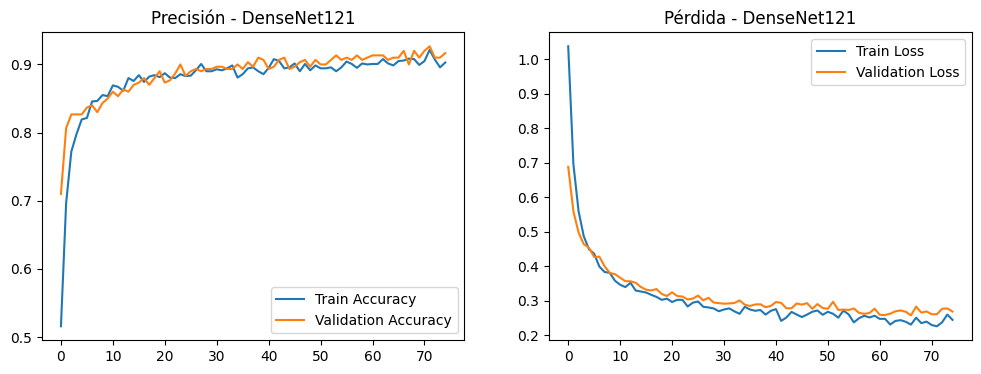

In [6]:
# @title CELDA 6-C: Entrenamiento con DenseNet121 (El Candidato Fuerte)
import tensorflow as tf
from tensorflow.keras import layers, models, applications, callbacks
import matplotlib.pyplot as plt
import os

# --- 1. GPU CHECK ---
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ GPU Configurada.")
    except RuntimeError as e:
        print(f"❌ Error GPU: {e}")

# --- 2. MODELO BASE (DenseNet121) ---
# DenseNet es famoso por aprovechar al máximo cada pixel
base_model = applications.DenseNet121(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3)
)
base_model.trainable = False

# --- 3. ARQUITECTURA ---
inputs = layers.Input(shape=(224, 224, 3))

# PREPROCESAMIENTO:
# 1. Tu dataset viene en [0, 1].
# 2. DenseNet prefiere recibir [0, 255] y luego usar su propia función.
x = layers.Rescaling(255.0)(inputs)
x = applications.densenet.preprocess_input(x) # Normalización específica de DenseNet

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x) 
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs, name="DenseNet121_Maiz")

# --- 4. COMPILACIÓN ---
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# --- 5. CALLBACKS ---
checkpoint_path = "mejor_modelo_densenet121.h5"

callbacks_list = [
    callbacks.ModelCheckpoint(
        checkpoint_path,
        save_best_only=True,
        monitor='val_accuracy',
        mode='max',
        verbose=1,
        save_weights_only=False
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

# --- 6. ENTRENAMIENTO ---
print(f"\n🚀 ENTRENANDO DENSENET121... (El rival de EfficientNet)")

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100, 
    callbacks=callbacks_list
)

# --- 7. GUARDAR Y GRAFICAR ---
model.save("modelo_final_densenet.h5")

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.title('Precisión - DenseNet121')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Pérdida - DenseNet121')
plt.legend()
plt.show()

🔍 Generando predicciones sobre el conjunto de prueba...
✅ Predicciones completadas.
------------------------------------------------------------

📊 REPORTE DE CLASIFICACIÓN (Métricas Oficiales):

              precision    recall  f1-score   support

  roya_comun     0.9703    1.0000    0.9849        98
        sana     0.8396    0.8476    0.8436       105
tizon_foliar     0.8298    0.7959    0.8125        98

    accuracy                         0.8804       301
   macro avg     0.8799    0.8812    0.8803       301
weighted avg     0.8790    0.8804    0.8795       301



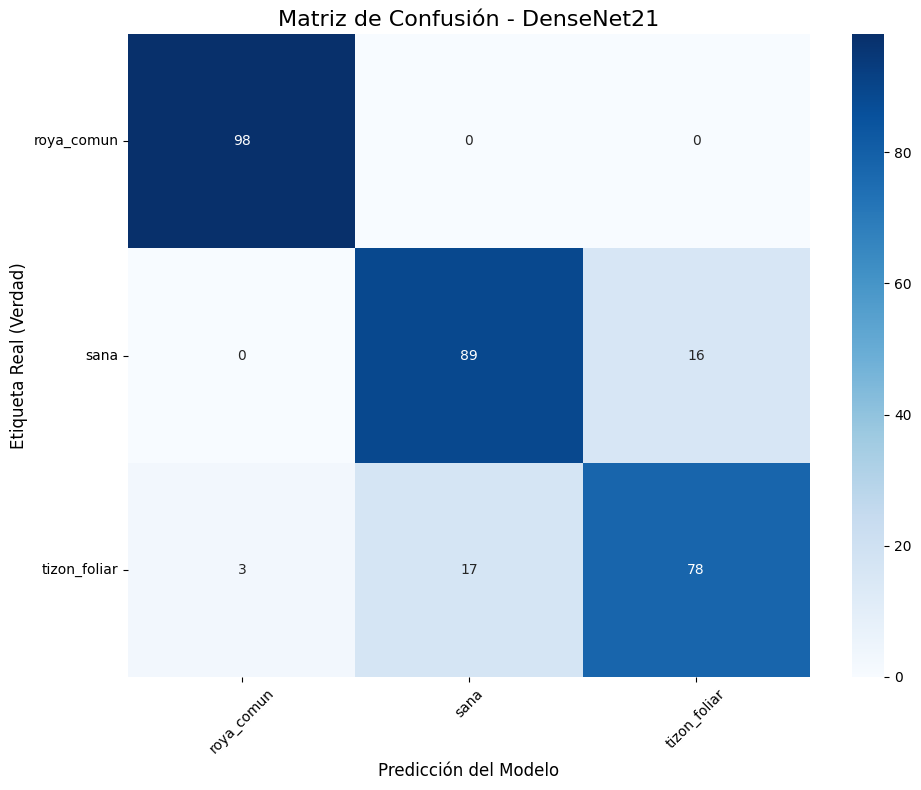

------------------------------------------------------------
🏆 EXACTITUD GLOBAL (Accuracy): 88.04%
------------------------------------------------------------


In [7]:
# @title CELDA 7: Evaluación de Métricas y Matriz de Confusión
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# --- 1. OBTENER PREDICCIONES Y ETIQUETAS REALES ---
print("🔍 Generando predicciones sobre el conjunto de prueba...")

# Extraemos las etiquetas verdaderas (y_true) y las predicciones (y_pred)
y_true = []
y_pred_probs = []

# Iteramos sobre el dataset de prueba (batch por batch para no saturar memoria)
for images, labels in test_dataset:
    # Predicción del modelo (probabilidades)
    probs = model.predict(images, verbose=0)
    
    # Guardamos resultados
    y_true.extend(labels.numpy())
    y_pred_probs.extend(probs)

# Convertimos a arrays de numpy
y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
# Convertimos probabilidades a etiquetas (0, 1, 2, 3) tomando el valor más alto
y_pred = np.argmax(y_pred_probs, axis=1)

print("✅ Predicciones completadas.")
print("-" * 60)

# --- 2. REPORTE DE CLASIFICACIÓN (TABLA DE MÉTRICAS) ---
print("\n📊 REPORTE DE CLASIFICACIÓN (Métricas Oficiales):\n")

report = classification_report(
    y_true, 
    y_pred, 
    target_names=class_names, # Usa los nombres de tus carpetas
    digits=4 # 4 decimales para mayor precisión
)
print(report)

# --- 3. MATRIZ DE CONFUSIÓN (GRÁFICO) ---
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True,         # Mostrar números dentro de los cuadros
    fmt='d',            # Formato entero (sin decimales)
    cmap='Blues',       # Color azul profesional
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Matriz de Confusión - DenseNet21', fontsize=16)
plt.ylabel('Etiqueta Real (Verdad)', fontsize=12)
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# --- 4. EXPLICACIÓN RÁPIDA ---
acc = np.sum(y_pred == y_true) / len(y_true)
print("-" * 60)
print(f"🏆 EXACTITUD GLOBAL (Accuracy): {acc:.2%}")
print("-" * 60)

📂 Abriendo explorador de archivos...
✅ Archivo seleccionado: tizon.png
🧠 Analizando imagen...


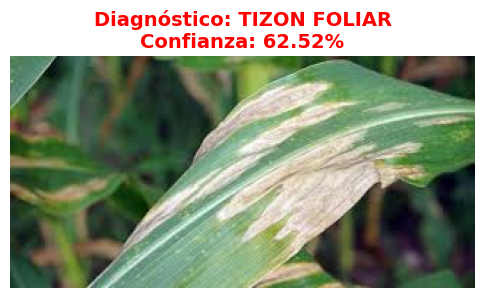

--------------------------------------------------
🌽 RESULTADO DEL DIAGNÓSTICO:
   ➤ Enfermedad Detectada: TIZON_FOLIAR
   ➤ Nivel de Confianza:   62.52%
   ➤ Tiempo de Análisis:   0.1686 seg
--------------------------------------------------
📊 Probabilidades por clase:
   - roya_comun          : 34.93% 
   - sana                : 2.55% 
   - tizon_foliar        : 62.52% ◄ GANADORA


In [4]:
# @title CELDA 13: Prueba con Imagen Real (Ventana Windows Directa)
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import tkinter as tk
from tkinter import filedialog

# --- 1. ABRIR VENTANA DE WINDOWS DIRECTAMENTE ---
print("📂 Abriendo explorador de archivos...")

# Crear la instancia de Tkinter
root = tk.Tk()

# TRUCOS PARA FORZAR LA VENTANA AL FRENTE (ENCIMA DE VS CODE/CHROME)
root.attributes('-topmost', True)  # Mantener siempre encima
root.lift()                        # Levantar la ventana
root.focus_force()                 # Robar el foco del teclado/mouse
root.withdraw()                    # Ocultar la caja gris fea, dejar solo el diálogo

# Abrir el explorador de archivos
file_path = filedialog.askopenfilename(
    parent=root,
    title="SELECCIONA UNA IMAGEN DE MAÍZ",
    filetypes=[("Imágenes", "*.jpg *.jpeg *.png *.bmp *.webp")]
)

# Destruir la instancia inmediatamente después de elegir
root.destroy()

# --- 2. VERIFICAR SELECCIÓN ---
if not file_path:
    print("❌ Cancelaste la selección o cerraste la ventana.")
else:
    print(f"✅ Archivo seleccionado: {os.path.basename(file_path)}")

    # --- 3. PREPROCESAMIENTO ---
    # Cargar y redimensionar a 224x224
    img_size = (224, 224) 
    
    # Cargar imagen para visualización (original)
    img_display = image.load_img(file_path)
    
    # Cargar imagen para el modelo (tensor)
    img_tensor = image.load_img(file_path, target_size=img_size)
    img_array = image.img_to_array(img_tensor)
    img_array = img_array / 255.0  # Normalizar [0, 1]
    
    # Crear lote de 1 imagen
    img_batch = np.expand_dims(img_array, axis=0)

    # --- 4. PREDICCIÓN ---
    print("🧠 Analizando imagen...")
    start = time.time()
    predictions = model.predict(img_batch, verbose=0)
    end = time.time()
    
    # --- 5. RESULTADOS ---
    predicted_idx = np.argmax(predictions[0])
    predicted_label = class_names[predicted_idx]
    confidence = np.max(predictions[0]) * 100
    total_time = end - start

    # --- 6. MOSTRAR REPORTE ---
    plt.figure(figsize=(6, 6))
    plt.imshow(img_display)
    plt.axis('off')
    
    # Colorear título según seguridad del modelo
    if confidence > 90:
        color = 'green'  # Muy seguro
    elif confidence > 70:
        color = 'orange' # Duda razonable
    else:
        color = 'red'    # Inseguro (Cuidado)

    plt.title(f"Diagnóstico: {predicted_label.replace('_', ' ').upper()}\nConfianza: {confidence:.2f}%", 
              color=color, fontsize=14, fontweight='bold')
    plt.show()

    print("-" * 50)
    print(f"🌽 RESULTADO DEL DIAGNÓSTICO:")
    print(f"   ➤ Enfermedad Detectada: {predicted_label.upper()}")
    print(f"   ➤ Nivel de Confianza:   {confidence:.2f}%")
    print(f"   ➤ Tiempo de Análisis:   {total_time:.4f} seg")
    print("-" * 50)
    
    print("📊 Probabilidades por clase:")
    for i, prob in enumerate(predictions[0]):
        # Resaltar la ganadora con una flecha
        marker = "◄ GANADORA" if i == predicted_idx else ""
        print(f"   - {class_names[i]:<20}: {prob*100:.2f}% {marker}")